# 🧳 Travel Reimbursement Approval Agent

A lightweight **agentic GenAI prototype** that reviews employee travel claims against a mock policy (Appendix A) and returns a structured decision: `APPROVE`, `PARTIAL_APPROVE`, `REJECT` or `MANUAL_REVIEW`.

## README

### How it works (architecture)
```
Claim JSON ─► intake + schema validation
                  │
                  ▼
        ┌──────────────────────┐      tool calls       ┌────────────────────────────┐
        │  LLM agent (Gemini)  │ ───────────────────►  │ lookup_policy (RAG-lite)   │
        │  function-calling    │ ◄───────────────────  │ get_claim                  │
        │  loop (max 8 steps)  │      tool results     │ check_eligibility          │
        └──────────┬───────────┘                       │ check_receipts             │
                   │ JSON decision                     │ check_limits (per-diem)    │
                   ▼                                   │ check_timeliness           │
        ┌──────────────────────┐                       │ check_approval_threshold   │
        │ Output validator +   │ ◄── deterministic ──  └────────────────────────────┘
        │ rule-engine guardrail│     reference engine
        └──────────┬───────────┘
                   ▼
   Structured JSON  +  audit trail  +  dashboard  +  interactive UI
```
* **LLM** decides *which* tools to call, reads their results, handles missing / conflicting info and writes the explanation.
* **Deterministic tools** do all the arithmetic and rule checks (LLMs are unreliable at maths).
* **Validator / guardrail** checks the LLM JSON against the schema and the rule engine. Amounts always come from the rule engine; if the LLM disagrees on the decision, the rule engine wins and the case is flagged in the audit trail.
* **No API key? No problem** – the notebook falls back to an *offline agent* that calls the same tools in a fixed sequence, so it **always runs top-to-bottom**.

### Setup (Google Colab)
1. Get a **free** Gemini API key at <https://aistudio.google.com/apikey>.
2. In Colab: left sidebar → 🔑 **Secrets** → *Add new secret* → name `GEMINI_API_KEY`, paste the key, enable *Notebook access*.
   (Locally you can instead run `export GEMINI_API_KEY=...`.)
3. **Runtime → Run all.** No other manual steps.

### Environment variables
| Variable | Required | Purpose |
|---|---|---|
| `GEMINI_API_KEY` | optional | Enables the LLM agent (Gemini free tier). Without it the offline fallback agent is used. |

### How to run the demo
* *Run all* → results table, audit trail, tests, dashboard (`UI SS_1.png` is saved next to the notebook), interactive UI, and the final JSON array in the **last code cell**.
* In the **Interactive UI** section, pick any claim (or paste your own JSON claim) and click **Evaluate claim**.

### Key design choices
Hybrid *LLM-for-judgement, code-for-arithmetic* design; manual review preferred over forced decisions; every decision cites `POL-*` rule ids. Full discussion in **Design Notes & Reasoning** near the end.

In [1]:
# 1) Dependencies: Colab already ships google-genai, pandas, matplotlib and ipywidgets.
#    We only install if something is missing (no -U, so Colab's own packages are never upgraded).
import importlib.util, subprocess, sys
for _pkg, _mod in [("google-genai", "google.genai"), ("ipywidgets", "ipywidgets")]:
    try:
        _found = importlib.util.find_spec(_mod) is not None
    except Exception:
        _found = False
    if not _found:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])
print("Dependencies OK")

Dependencies OK


In [3]:
# 2) Imports & configuration
import os, re, json, time, datetime as dt
import pandas as pd

MODEL_CANDIDATES = ["gemini-2.5-flash", "gemini-2.0-flash"]   # free-tier friendly; 2nd is a fallback model
MAX_AGENT_STEPS = 8                                           # hard cap on tool-calling loop

# --- API key: Colab Secret first, then environment variable --------------------------------
GEMINI_API_KEY = None
try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    pass
GEMINI_API_KEY = GEMINI_API_KEY or os.environ.get("GEMINI_API_KEY")

LLM_ENABLED, client, types = False, None, None
if GEMINI_API_KEY:
    try:
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=GEMINI_API_KEY)
        LLM_ENABLED = True
    except Exception as e:
        print("⚠️ Could not initialise Gemini client:", e)

print("Agent mode :", "LLM (Gemini function-calling)" if LLM_ENABLED else "OFFLINE fallback (no GEMINI_API_KEY found)")

Agent mode : LLM (Gemini function-calling)


## 1. Policy context (Appendix A) & limit table
The policy is stored as a small knowledge base keyed by stable rule ids. `lookup_policy()` is the agent's **retrieval tool** (keyword-overlap scoring – deliberately lightweight; swap for embeddings if the policy grows).

In [4]:
POLICY = {
 "POL-CAT-01": {"title": "Eligible categories",
   "text": "Reimbursable when incurred for a documented business purpose: airfare (economy only), lodging, meals (per-diem limits), ground transport (taxi, rideshare, train, rental car, parking), conference/registration fees.",
   "keywords": "eligible category categories airfare lodging hotel meals ground transport taxi rideshare train rental parking conference registration fees"},
 "POL-CAT-02": {"title": "Ineligible items",
   "text": "Never reimbursable; rejected (deducted in full): alcohol and minibar, spa, gym, personal entertainment, in-room movies, personal shopping, gifts, traffic fines, penalties, late fees, any personal non-business expense.",
   "keywords": "ineligible alcohol minibar spa gym entertainment movies shopping gifts fines penalties late fees personal reject never"},
 "POL-PD-01": {"title": "Meals per-diem",
   "text": "Maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed.",
   "keywords": "meals meal per-diem per diem daily cap limit dinner lunch breakfast food"},
 "POL-PD-02": {"title": "Lodging nightly cap",
   "text": "Maximum $200 per night. Amounts above the nightly cap are deducted; the rest is reimbursed.",
   "keywords": "lodging hotel night nightly cap limit room accommodation"},
 "POL-PD-03": {"title": "Ground transport cap",
   "text": "Maximum $50 per day. Amounts above the cap are deducted.",
   "keywords": "ground transport taxi rideshare train rental car parking daily cap limit"},
 "POL-AIR-01": {"title": "Airfare class",
   "text": "Only economy class airfare is reimbursable. Business/first-class fares are a policy exception and must be routed to Manual Review (not auto-deducted, because a pre-approval may exist).",
   "keywords": "airfare air flight class economy business first exception pre-approval"},
 "POL-RCT-01": {"title": "Receipt required above $25",
   "text": "Any single line item greater than $25 requires an attached, itemized receipt. Airfare and lodging always require a receipt regardless of amount.",
   "keywords": "receipt receipts itemized required attached above 25 airfare lodging"},
 "POL-RCT-02": {"title": "Missing receipt handling",
   "text": "If a receipt is missing for an item that requires one, the item is not silently rejected - the claim is routed to Manual Review so the reviewer can request the receipt.",
   "keywords": "missing receipt manual review request reviewer"},
 "POL-APR-01": {"title": "Auto-approve tier",
   "text": "Total reimbursable <= $500: may be auto-approved by the agent if fully compliant.",
   "keywords": "approval threshold tier auto-approve total 500"},
 "POL-APR-02": {"title": "Manager tier",
   "text": "Total > $500 and <= $2,000: eligible for approval, treated as approvable when fully compliant.",
   "keywords": "approval threshold tier manager total 500 2000"},
 "POL-APR-03": {"title": "Director / Manual-Review tier",
   "text": "Total > $2,000 exceeds the agent's auto-approval authority and must be routed to Manual Review (director approval required), even if otherwise compliant.",
   "keywords": "approval threshold tier director manual review total 2000 high value authority"},
 "POL-TIME-01": {"title": "Submission window",
   "text": "Claims must be submitted within 30 days of the expense date. Late claims are routed to Manual Review.",
   "keywords": "timeliness submission window 30 days late submitted expense date"},
}

# Limit table / approval matrix (used by the deterministic tools)
LIMITS = {                       # category -> (rule id, cap, unit)
    "meals":            ("POL-PD-01", 75.0,  "day"),
    "lodging":          ("POL-PD-02", 200.0, "night"),
    "ground_transport": ("POL-PD-03", 50.0,  "day"),
}
RECEIPT_THRESHOLD   = 25.0
ALWAYS_RECEIPT      = {"airfare", "lodging"}
AUTO_APPROVE_MAX    = 500.0
MANAGER_MAX         = 2000.0
SUBMISSION_WINDOW_D = 30

ELIGIBLE_CATS   = {"airfare", "lodging", "meals", "ground_transport", "conference_fees"}
INELIGIBLE_CATS = {"alcohol", "minibar", "spa", "gym", "entertainment", "movies", "shopping",
                   "gifts", "fines", "penalties", "late_fees", "personal"}
CATEGORY_ALIASES = {"hotel": "lodging", "flight": "airfare", "meal": "meals", "conference": "conference_fees",
                    "registration": "conference_fees", "taxi": "ground_transport", "rideshare": "ground_transport",
                    "train": "ground_transport", "rental_car": "ground_transport", "parking": "ground_transport",
                    "ground_transportation": "ground_transport", "gift": "gifts", "fine": "fines",
                    "penalty": "penalties", "late_fee": "late_fees", "movie": "movies"}
INELIGIBLE_WORDS = r"\b(alcohol|wine|beer|liquor|cocktails?|minibar|spa|massage|gym|movies?|gifts?|souvenirs?|fines?|penalty|penalties|late fee|personal)\b"


def lookup_policy(query: str) -> dict:
    """Retrieve the most relevant travel-policy rules (with their POL-* ids) for a free-text query.

    Args:
        query: Topic or question, e.g. 'meal per diem limit' or 'missing receipt'.
    Returns:
        A dict with the top matching policy rules (id, title, text).
    """
    q = set(re.findall(r"[a-z0-9\-\$]+", query.lower()))
    exact = [rid for rid in POLICY if rid.lower() in query.lower()]
    scored = []
    for rid, r in POLICY.items():
        bag = set(re.findall(r"[a-z0-9\-\$]+", (r["keywords"] + " " + r["title"]).lower()))
        score = len(q & bag) + (5 if rid in exact else 0)
        if score:
            scored.append((score, rid))
    scored.sort(reverse=True)
    top = [rid for _, rid in scored[:4]]
    return {"query": query, "rules": [{"id": rid, "title": POLICY[rid]["title"], "text": POLICY[rid]["text"]} for rid in top]}

print(json.dumps(lookup_policy("meal per diem limit"), indent=1)[:600])

{
 "query": "meal per diem limit",
 "rules": [
  {
   "id": "POL-PD-01",
   "title": "Meals per-diem",
   "text": "Maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed."
  },
  {
   "id": "POL-PD-03",
   "title": "Ground transport cap",
   "text": "Maximum $50 per day. Amounts above the cap are deducted."
  },
  {
   "id": "POL-PD-02",
   "title": "Lodging nightly cap",
   "text": "Maximum $200 per night. Amounts above the nightly cap are deducted; the rest is reimbursed."
  }
 ]
}


## 2. Claim intake (Appendix B)
Claims are accepted as **JSON** and schema-validated. The five sample claims below are a direct transcription of Appendix B. `quantity` / `unit` simply record the "3 days", "2 nights" etc. already stated in each description so tools can apply per-day / per-night caps.

In [5]:
SAMPLE_CLAIMS_JSON = """
[
 {"claim_id": "CLM-001", "employee": "A. Rivera", "purpose": "Attend 2-day industry conference (business)",
  "trip_start": "2026-06-10", "trip_end": "2026-06-12", "submitted": "2026-06-20",
  "items": [
   {"category": "airfare",         "description": "Round-trip economy airfare", "amount": 420.00, "receipt": true, "quantity": 1, "unit": "trip"},
   {"category": "lodging",         "description": "Hotel, 2 nights @ $180",      "amount": 360.00, "receipt": true, "quantity": 2, "unit": "night"},
   {"category": "meals",           "description": "Meals, 3 days @ ~$60/day",    "amount": 180.00, "receipt": true, "quantity": 3, "unit": "day"},
   {"category": "conference_fees", "description": "Conference registration",     "amount": 150.00, "receipt": true, "quantity": 1, "unit": "fee"}
  ]},
 {"claim_id": "CLM-002", "employee": "B. Osei", "purpose": "Weekend hotel stay",
  "trip_start": "2026-06-14", "trip_end": "2026-06-15", "submitted": "2026-06-25",
  "items": [
   {"category": "spa",     "description": "Hotel spa package", "amount": 300.00, "receipt": true, "quantity": 1, "unit": "item"},
   {"category": "minibar", "description": "In-room minibar",   "amount": 80.00,  "receipt": true, "quantity": 1, "unit": "item"}
  ]},
 {"claim_id": "CLM-003", "employee": "C. Nakamura", "purpose": "Client site visit (business)",
  "trip_start": "2026-06-08", "trip_end": "2026-06-10", "submitted": "2026-06-22",
  "items": [
   {"category": "airfare", "description": "Round-trip economy airfare", "amount": 300.00, "receipt": true, "quantity": 1, "unit": "trip"},
   {"category": "lodging", "description": "Hotel, 2 nights @ $250",      "amount": 500.00, "receipt": true, "quantity": 2, "unit": "night"},
   {"category": "meals",   "description": "Meals, 2 days @ $70/day",     "amount": 140.00, "receipt": true, "quantity": 2, "unit": "day"}
  ]},
 {"claim_id": "CLM-004", "employee": "D. Fischer", "purpose": "International vendor negotiation (business)",
  "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted": "2026-06-28",
  "items": [
   {"category": "airfare", "description": "Business-class international airfare", "amount": 2400.00, "receipt": true,  "quantity": 1, "unit": "trip"},
   {"category": "lodging", "description": "Hotel, 3 nights",                       "amount": 600.00,  "receipt": false, "quantity": 3, "unit": "night"}
  ]},
 {"claim_id": "CLM-005", "employee": "E. Haddad", "purpose": "Client dinner / business development",
  "trip_start": "2026-06-11", "trip_end": "2026-06-11", "submitted": "2026-06-24",
  "items": [
   {"category": "meals", "description": "Client dinner for 4 (business development)", "amount": 220.00, "receipt": false, "quantity": 1, "unit": "day"}
  ]}
]
"""

CLAIMS = {}          # in-memory claim store (claim_id -> claim dict)

def parse_date(s):
    return dt.datetime.strptime(str(s), "%Y-%m-%d").date()

def validate_claim_schema(claim: dict) -> list:
    """Return a list of schema problems (empty list = valid)."""
    problems = []
    for f in ("claim_id", "trip_start", "trip_end", "submitted", "items"):
        if f not in claim or claim[f] in (None, "", []):
            problems.append(f"missing field '{f}'")
    for f in ("trip_start", "trip_end", "submitted"):
        try:
            if f in claim: parse_date(claim[f])
        except Exception:
            problems.append(f"invalid date in '{f}' (expected YYYY-MM-DD)")
    for i, it in enumerate(claim.get("items") or []):
        for f in ("category", "amount", "receipt"):
            if f not in it:
                problems.append(f"item[{i}] missing '{f}'")
        try:
            if float(it.get("amount", 0)) <= 0:
                problems.append(f"item[{i}] amount must be > 0")
        except Exception:
            problems.append(f"item[{i}] amount is not numeric")
    return problems

def load_claims(json_text: str) -> list:
    """Parse a JSON claim (object) or list of claims into the store. Returns the claim ids."""
    data = json.loads(json_text)
    data = data if isinstance(data, list) else [data]
    ids = []
    for c in data:
        CLAIMS[c.get("claim_id", f"CLM-UNKNOWN-{len(CLAIMS)+1}")] = c
        ids.append(c.get("claim_id"))
    return ids

SAMPLE_IDS = load_claims(SAMPLE_CLAIMS_JSON)
pd.DataFrame([{"claim_id": c["claim_id"], "employee": c["employee"], "purpose": c["purpose"],
               "items": len(c["items"]), "total_claimed": sum(i["amount"] for i in c["items"])}
              for c in CLAIMS.values()])

,claim_id,employee,purpose,items,total_claimed
0,CLM-001,A. Rivera,Attend 2-day industry conference (business),4,1110.0
1,CLM-002,B. Osei,Weekend hotel stay,2,380.0
2,CLM-003,C. Nakamura,Client site visit (business),3,940.0
3,CLM-004,D. Fischer,International vendor negotiation (business),2,3000.0
4,CLM-005,E. Haddad,Client dinner / business development,1,220.0


## 3. Deterministic rule engine & agent tools
`analyze_claim()` is the single source of truth for the arithmetic. Each **tool** exposed to the LLM returns one slice of that analysis (eligibility, receipts, limits, timeliness, threshold), so the LLM has to *combine* several tool outputs to reach a decision. The same engine later acts as the **guardrail** on the LLM's final answer.

In [6]:
def normalize_category(cat: str) -> str:
    c = re.sub(r"[\s\-/]+", "_", str(cat).strip().lower())
    return CATEGORY_ALIASES.get(c, c)

def detect_airfare_class(description: str) -> str:
    d = description.lower()
    if re.search(r"\b(business|first)[\s\-]*class\b", d) or re.search(r"\b(business|first)\b", d):
        return "business/first"
    return "economy"

def money(x): return round(float(x) + 1e-9, 2)

def analyze_item(item: dict) -> dict:
    cat    = normalize_category(item["category"])
    amt    = money(item["amount"])
    qty    = max(int(item.get("quantity") or 1), 1)
    desc   = str(item.get("description", ""))
    has_rc = bool(item.get("receipt"))
    r = {"category": cat, "description": desc, "claimed": amt, "eligible": True, "allowed": amt, "deducted": 0.0,
         "refs": [], "flags": [], "receipt_required": False, "receipt_attached": has_rc, "receipt_missing": False,
         "cap": None, "note": "within policy"}

    # ---- eligibility (POL-CAT-01 / POL-CAT-02)
    if cat in INELIGIBLE_CATS:
        r.update(eligible=False, allowed=0.0, deducted=amt, refs=["POL-CAT-02"], note="ineligible item - deducted in full (POL-CAT-02)")
        return r
    if cat in ELIGIBLE_CATS:
        r["refs"].append("POL-CAT-01")
    else:
        r["flags"].append("UNKNOWN_CATEGORY"); r["refs"].append("POL-CAT-01")
    if cat in ELIGIBLE_CATS and re.search(INELIGIBLE_WORDS, desc.lower()):
        r["flags"].append("POSSIBLE_INELIGIBLE_CONTENT"); r["refs"].append("POL-CAT-02")

    # ---- receipts (POL-RCT-01/02)
    if amt > RECEIPT_THRESHOLD or cat in ALWAYS_RECEIPT:
        r["receipt_required"] = True; r["refs"].append("POL-RCT-01")
        if not has_rc:
            r["receipt_missing"] = True; r["flags"].append("MISSING_RECEIPT"); r["refs"].append("POL-RCT-02")

    # ---- airfare class (POL-AIR-01)
    if cat == "airfare":
        r["refs"].append("POL-AIR-01")
        r["fare_class"] = detect_airfare_class(desc)
        if r["fare_class"] != "economy":
            r["flags"].append("AIR_CLASS_EXCEPTION")

    # ---- per-diem / caps (POL-PD-01..03)
    if cat in LIMITS:
        rid, cap, unit = LIMITS[cat]
        cap_total = money(cap * qty)
        r["cap"] = {"rule": rid, "per_unit": cap, "unit": unit, "quantity": qty, "cap_total": cap_total}
        r["refs"].append(rid)
        if amt > cap_total:
            r["allowed"] = cap_total; r["deducted"] = money(amt - cap_total)
            r["flags"].append("OVER_CAP")
            r["note"] = f"exceeds ${cap:g}/{unit} cap x {qty} {unit}(s) = ${cap_total:,.2f}; excess ${r['deducted']:,.2f} deducted ({rid})"
        # ambiguity: group / client meals make a per-person-per-day cap unclear
        if cat == "meals":
            m = re.search(r"\bfor\s+(\d+)\b", desc.lower())
            if (m and int(m.group(1)) > 1) or "client" in desc.lower():
                r["flags"].append("AMBIGUOUS_BUSINESS_MEAL")
    r["refs"] = list(dict.fromkeys(r["refs"]))
    return r


def tier_for(total: float):
    if total <= AUTO_APPROVE_MAX: return "POL-APR-01", "AUTO_APPROVE (<= $500)"
    if total <= MANAGER_MAX:      return "POL-APR-02", "MANAGER (> $500 and <= $2,000)"
    return "POL-APR-03", "DIRECTOR (> $2,000) - exceeds agent authority"


def analyze_claim(claim: dict) -> dict:
    """Full deterministic evaluation of a claim. Returns the 'ground truth' used for tools + guardrail."""
    problems = validate_claim_schema(claim)
    cid = claim.get("claim_id", "UNKNOWN")
    if problems:
        return {"claim_id": cid, "decision": "MANUAL_REVIEW", "approved": 0.0, "deducted": 0.0, "total_claimed": 0.0,
                "total_reimbursable": 0.0, "items": [], "missing_docs": [], "refs": [],
                "manual_reasons": [{"code": "INVALID_INPUT", "msg": "claim failed schema validation: " + "; ".join(problems), "refs": []}],
                "timeliness": None, "tier": None}

    items = [analyze_item(i) for i in claim["items"]]
    total_claimed      = money(sum(i["claimed"] for i in items))
    total_reimbursable = money(sum(i["allowed"] for i in items))
    total_ineligible   = money(sum(i["deducted"] for i in items if not i["eligible"]))
    total_percap       = money(sum(i["deducted"] for i in items if i["eligible"]))

    # timeliness (POL-TIME-01) - measured from the EARLIEST expense date (trip_start) = conservative
    days_late = (parse_date(claim["submitted"]) - parse_date(claim["trip_start"])).days
    timeliness = {"days_since_expense": days_late, "window_days": SUBMISSION_WINDOW_D, "late": days_late > SUBMISSION_WINDOW_D, "rule": "POL-TIME-01"}

    tier_rule, tier_label = tier_for(total_reimbursable)

    reasons, missing_docs, refs = [], [], []
    for i in items:
        refs += i["refs"]
        for fl in i["flags"]:
            if fl == "MISSING_RECEIPT":
                reasons.append({"code": fl, "refs": ["POL-RCT-01", "POL-RCT-02"],
                                "msg": f"required itemized receipt missing for {i['category']} (${i['claimed']:,.2f})"})
                missing_docs.append(f"Itemized receipt for {i['category']} (${i['claimed']:,.2f})")
            elif fl == "AIR_CLASS_EXCEPTION":
                reasons.append({"code": fl, "refs": ["POL-AIR-01"],
                                "msg": f"{i['category']} is {i.get('fare_class')} class (${i['claimed']:,.2f}) - policy exception, pre-approval may exist"})
            elif fl == "AMBIGUOUS_BUSINESS_MEAL":
                reasons.append({"code": fl, "refs": ["POL-PD-01"],
                                "msg": f"group/client meal (${i['claimed']:,.2f}) - unclear how the $75/day per-diem applies; needs reviewer judgement"})
            elif fl == "UNKNOWN_CATEGORY":
                reasons.append({"code": fl, "refs": ["POL-CAT-01"], "msg": f"category '{i['category']}' is not in the policy"})
            elif fl == "POSSIBLE_INELIGIBLE_CONTENT":
                reasons.append({"code": fl, "refs": ["POL-CAT-02"], "msg": f"{i['category']} description suggests ineligible content ('{i['description']}')"})
    if tier_rule == "POL-APR-03":
        reasons.append({"code": "OVER_AUTHORITY", "refs": ["POL-APR-03"],
                        "msg": f"total reimbursable ${total_reimbursable:,.2f} exceeds $2,000 agent authority - director approval required"})
    if timeliness["late"]:
        reasons.append({"code": "LATE_SUBMISSION", "refs": ["POL-TIME-01"],
                        "msg": f"submitted {days_late} days after expense date (window {SUBMISSION_WINDOW_D})"})

    if total_reimbursable > 0: refs.append(tier_rule)
    if timeliness["late"]: refs.append("POL-TIME-01")
    refs += [r for x in reasons for r in x["refs"]]

    # ---- decision (Appendix A "Decision Guidance")
    if reasons:
        decision, approved, deducted = "MANUAL_REVIEW", 0.0, 0.0           # pending reviewer
    elif total_reimbursable == 0:
        decision, approved, deducted = "REJECT", 0.0, total_claimed
    elif total_ineligible + total_percap > 0:
        decision, approved, deducted = "PARTIAL_APPROVE", total_reimbursable, money(total_claimed - total_reimbursable)
    else:
        decision, approved, deducted = "APPROVE", total_reimbursable, 0.0

    return {"claim_id": cid, "decision": decision, "approved": approved, "deducted": deducted,
            "total_claimed": total_claimed, "total_reimbursable": total_reimbursable,
            "total_ineligible": total_ineligible, "total_per_diem_deducted": total_percap,
            "items": items, "missing_docs": missing_docs, "refs": sorted(set(refs)),
            "manual_reasons": reasons, "timeliness": timeliness, "tier": {"rule": tier_rule, "label": tier_label}}


# ------------------------------------------------------------------ TOOLS exposed to the LLM
def _claim_or_error(claim_id):
    return (CLAIMS.get(claim_id), None) if claim_id in CLAIMS else (None, {"error": f"unknown claim_id '{claim_id}'"})

def get_claim(claim_id: str) -> dict:
    """Fetch the raw claim (employee, trip dates, submission date and line items) by its id.

    Args:
        claim_id: e.g. 'CLM-001'.
    """
    c, err = _claim_or_error(claim_id)
    return err or c

def check_eligibility(claim_id: str) -> dict:
    """Check every line item against eligible (POL-CAT-01) and ineligible (POL-CAT-02) categories.

    Args:
        claim_id: e.g. 'CLM-001'.
    """
    c, err = _claim_or_error(claim_id)
    if err: return err
    a = analyze_claim(c)
    return {"claim_id": claim_id, "items": [{"category": i["category"], "claimed": i["claimed"], "eligible": i["eligible"],
            "flags": [f for f in i["flags"] if f in ("UNKNOWN_CATEGORY", "POSSIBLE_INELIGIBLE_CONTENT")], "refs": [r for r in i["refs"] if r.startswith("POL-CAT")]}
            for i in a["items"]], "total_ineligible_amount": a.get("total_ineligible", 0.0), "schema_problems": validate_claim_schema(c)}

def check_receipts(claim_id: str) -> dict:
    """Check receipt completeness: a receipt is required for any line item > $25, and always for airfare and lodging.

    Args:
        claim_id: e.g. 'CLM-001'.
    """
    c, err = _claim_or_error(claim_id)
    if err: return err
    a = analyze_claim(c)
    return {"claim_id": claim_id, "items": [{"category": i["category"], "claimed": i["claimed"], "receipt_required": i["receipt_required"],
            "receipt_attached": i["receipt_attached"], "receipt_missing": i["receipt_missing"]} for i in a["items"] if i["eligible"]],
            "missing_docs": a["missing_docs"], "rules": ["POL-RCT-01", "POL-RCT-02"],
            "routing_hint": "any missing required receipt => MANUAL_REVIEW (POL-RCT-02), never silent rejection"}

def check_limits(claim_id: str) -> dict:
    """Apply per-diem / category limits (meals $75/day, lodging $200/night, ground transport $50/day) and the airfare class rule.
    Returns allowed vs deducted amount per item, plus ambiguity flags.

    Args:
        claim_id: e.g. 'CLM-001'.
    """
    c, err = _claim_or_error(claim_id)
    if err: return err
    a = analyze_claim(c)
    return {"claim_id": claim_id, "items": [{"category": i["category"], "claimed": i["claimed"], "cap": i["cap"], "allowed": i["allowed"],
            "deducted": i["deducted"], "fare_class": i.get("fare_class"), "flags": [f for f in i["flags"] if f in ("OVER_CAP", "AIR_CLASS_EXCEPTION", "AMBIGUOUS_BUSINESS_MEAL")],
            "note": i["note"]} for i in a["items"] if i["eligible"]],
            "total_per_diem_deducted": a.get("total_per_diem_deducted", 0.0),
            "routing_hint": "business/first class airfare => MANUAL_REVIEW (POL-AIR-01); ambiguous group meal => MANUAL_REVIEW"}

def check_timeliness(claim_id: str) -> dict:
    """Check the 30-day submission window (POL-TIME-01), measured from the earliest expense date.

    Args:
        claim_id: e.g. 'CLM-001'.
    """
    c, err = _claim_or_error(claim_id)
    if err: return err
    return {"claim_id": claim_id, **analyze_claim(c)["timeliness"]}

def check_approval_threshold(claim_id: str) -> dict:
    """Compute the total reimbursable amount (after per-diem deductions and ineligible items) and map it to the approval tier.

    Args:
        claim_id: e.g. 'CLM-001'.
    """
    c, err = _claim_or_error(claim_id)
    if err: return err
    a = analyze_claim(c)
    return {"claim_id": claim_id, "total_claimed": a["total_claimed"], "total_reimbursable": a["total_reimbursable"],
            "total_deducted_so_far": money(a["total_claimed"] - a["total_reimbursable"]), "tier_rule": a["tier"]["rule"] if a["tier"] else None,
            "tier": a["tier"]["label"] if a["tier"] else None,
            "routing_hint": "tier POL-APR-03 (> $2,000) must go to MANUAL_REVIEW even if otherwise compliant"}

TOOL_REGISTRY = {f.__name__: f for f in (get_claim, lookup_policy, check_eligibility, check_receipts,
                                         check_limits, check_timeliness, check_approval_threshold)}
print("Tools available to the agent:", list(TOOL_REGISTRY))

Tools available to the agent: ['get_claim', 'lookup_policy', 'check_eligibility', 'check_receipts', 'check_limits', 'check_timeliness', 'check_approval_threshold']


## 4. The agent (LLM tool-calling loop + offline fallback)
* **LLM mode** – Gemini function calling. Automatic calling is *disabled* so we run the loop ourselves: that lets us cap steps, log every tool call (audit trail) and record `tools_used` from what was *actually* called rather than what the model claims.
* **Offline mode** – if no key is set or the API fails after retries, an offline agent calls the same tools in a fixed order and composes the answer from the rule engine. Reliability over elegance.

In [7]:
SYSTEM_PROMPT = """You are a Travel Reimbursement Approval Agent for a finance team. Evaluate ONE claim against the company policy
using the tools provided. Never do arithmetic or policy checks in your head - use the tools.

WORKFLOW
1. Call lookup_policy to ground yourself in the relevant POL-* rules, and get_claim to read the claim.
2. Call check_eligibility, check_limits, check_receipts, check_timeliness and check_approval_threshold.
3. Combine the results and decide. If tool results conflict or something is ambiguous, prefer MANUAL_REVIEW.

DECISION RULES (Appendix A)
- APPROVE: every item eligible, all required receipts present, all within caps, total reimbursable <= $2,000, no exceptions.
- PARTIAL_APPROVE: claim is valid but some amounts exceed per-diem caps or some items are ineligible; reimburse up to caps, deduct the rest.
- REJECT: all claimed items are ineligible (POL-CAT-02), nothing reimbursable.
- MANUAL_REVIEW: any ambiguity, policy exception (e.g. business/first class airfare, POL-AIR-01), missing required receipt (POL-RCT-02),
  total reimbursable > $2,000 (POL-APR-03), late submission (POL-TIME-01), or conflicting information. Prefer MANUAL_REVIEW over forcing a decision.
- For MANUAL_REVIEW set approved_amount = 0 and deducted_amount = 0 (the decision is pending the reviewer).
- Otherwise approved_amount = total reimbursable after deductions and deducted_amount = total claimed - approved_amount.

FINAL ANSWER: reply with ONLY a JSON object (no markdown fences) with exactly these keys:
{"decision": "APPROVE|PARTIAL_APPROVE|REJECT|MANUAL_REVIEW", "approved_amount": number, "deducted_amount": number,
 "missing_docs": [strings], "policy_refs": ["POL-..."], "confidence": number between 0 and 1, "explanation": "2-4 sentences citing POL ids and amounts"}"""


def call_tool(name: str, args: dict, trace: list):
    """Execute a registered tool, record it in the audit trace."""
    fn = TOOL_REGISTRY.get(name)
    try:
        result = fn(**args) if fn else {"error": f"unknown tool '{name}'"}
    except Exception as e:
        result = {"error": f"tool failed: {e}"}
    trace.append({"tool": name, "args": args, "result": result})
    return result


def _generate_with_retry(model, contents, config, retries=4):
    delay = 6
    for attempt in range(retries):
        try:
            return client.models.generate_content(model=model, contents=contents, config=config)
        except Exception as e:
            transient = any(k in str(e) for k in ("429", "500", "503", "RESOURCE_EXHAUSTED", "UNAVAILABLE", "overloaded"))
            if transient and attempt < retries - 1:
                time.sleep(delay); delay *= 2
                continue
            raise


def _llm_loop(model, claim_id, trace):
    config = types.GenerateContentConfig(
        system_instruction=SYSTEM_PROMPT, temperature=0.0,
        tools=list(TOOL_REGISTRY.values()),
        automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True))
    contents = [types.Content(role="user", parts=[types.Part.from_text(text=f"Evaluate claim {claim_id} and return the final JSON decision.")])]
    for step in range(MAX_AGENT_STEPS):
        resp = _generate_with_retry(model, contents, config)
        cand = resp.candidates[0]
        parts = (cand.content.parts if cand.content else None) or []
        contents.append(cand.content)
        calls = [p.function_call for p in parts if getattr(p, "function_call", None)]
        if not calls:                                      # model produced its final answer
            return "".join(p.text for p in parts if getattr(p, "text", None))
        responses = []
        for fc in calls:                                   # model may request several tools in parallel
            result = call_tool(fc.name, dict(fc.args or {}), trace)
            responses.append(types.Part.from_function_response(name=fc.name, response={"result": result}))
        contents.append(types.Content(role="user", parts=responses))
    raise RuntimeError(f"agent exceeded {MAX_AGENT_STEPS} steps without a final answer")


def run_llm_agent(claim_id):
    last_err = None
    for model in MODEL_CANDIDATES:
        trace = []
        try:
            return model, _llm_loop(model, claim_id, trace), trace
        except Exception as e:
            last_err = e
            print(f"   ⚠️ {model} failed for {claim_id}: {str(e)[:120]}")
    raise RuntimeError(f"all models failed: {last_err}")


def run_offline_agent(claim_id):
    """Deterministic fallback agent: same tools, fixed plan."""
    trace = []
    call_tool("get_claim", {"claim_id": claim_id}, trace)
    call_tool("lookup_policy", {"query": "eligible ineligible categories per diem limits receipts approval threshold timeliness airfare class"}, trace)
    for t in ("check_eligibility", "check_limits", "check_receipts", "check_timeliness", "check_approval_threshold"):
        call_tool(t, {"claim_id": claim_id}, trace)
    return trace


def parse_llm_json(text: str):
    text = re.sub(r"```(?:json)?", "", text or "").strip()
    s, e = text.find("{"), text.rfind("}")
    if s == -1 or e == -1: raise ValueError("no JSON object in LLM output")
    return json.loads(text[s:e + 1])

## 5. Output validator, guardrail & `process_claim()`
The validator enforces the output contract (exact fields, enums, numeric types) and reconciles the LLM answer with the rule engine:
* **amounts, missing docs** → always from the rule engine (maths must be exact)
* **decision** → if the LLM disagrees, the rule engine wins, confidence is capped and the override is logged
* **policy_refs** → union of rule-engine refs and any *valid* `POL-*` ids the LLM cited (hallucinated ids dropped)

In [8]:
DECISIONS = {"APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"}
OUTPUT_FIELDS = ["claim_id", "decision", "approved_amount", "deducted_amount", "missing_docs",
                 "policy_refs", "confidence", "explanation", "tools_used"]
AUDIT = {}      # claim_id -> audit trail (mode, tool calls, guardrail notes)


def template_explanation(t: dict) -> str:
    d = t["decision"]
    if d == "MANUAL_REVIEW":
        why = "; ".join(f"{r['msg']} [{', '.join(r['refs']) or 'n/a'}]" for r in t["manual_reasons"])
        extra = f" Provisional reimbursable total after caps: ${t['total_reimbursable']:,.2f}." if t["items"] else ""
        return f"Routed to MANUAL_REVIEW - {why}.{extra} No amount is approved or deducted until the reviewer resolves this."
    if d == "REJECT":
        its = ", ".join(f"{i['category']} (${i['claimed']:,.2f})" for i in t["items"])
        return f"All claimed items are ineligible under POL-CAT-02 ({its}); ${t['deducted']:,.2f} deducted in full, nothing reimbursable."
    ded = [f"{i['category']}: ${i['deducted']:,.2f} deducted - {i['note']}" for i in t["items"] if i["deducted"] > 0]
    tier = t["tier"]
    base = f"Total reimbursable ${t['approved']:,.2f} falls in tier {tier['rule']} - {tier['label']}; all required receipts present and submitted on time (POL-RCT-01, POL-TIME-01)."
    if d == "PARTIAL_APPROVE":
        return "Claim is valid but amounts exceed policy caps. " + " | ".join(ded) + ". " + base
    return "All items eligible (POL-CAT-01), within per-diem limits, receipts attached. " + base


def reconcile(parsed, truth, tools_used, llm_used=True):
    """Validate the LLM JSON and combine it with the rule-engine result. Returns (result_dict, notes)."""
    notes = []
    parsed = parsed if (llm_used and isinstance(parsed, dict)) else {}
    llm_dec = str(parsed.get("decision", "")).upper().strip()
    if llm_used:
        if llm_dec not in DECISIONS:
            notes.append(f"invalid/missing LLM decision '{llm_dec}' -> rule-engine decision used")
        elif llm_dec != truth["decision"]:
            notes.append(f"GUARDRAIL OVERRIDE: LLM said {llm_dec}, rule engine says {truth['decision']} -> rule engine used")
        for k, tk in (("approved_amount", "approved"), ("deducted_amount", "deducted")):
            try:
                if abs(float(parsed.get(k)) - truth[tk]) > 0.01:
                    notes.append(f"LLM {k}={parsed.get(k)} corrected to {truth[tk]}")
            except Exception:
                notes.append(f"LLM {k} missing/non-numeric -> {truth[tk]} used")
    agree = (llm_dec == truth["decision"])

    explanation = parsed.get("explanation")
    if not (agree and isinstance(explanation, str) and len(explanation.strip()) > 20):
        explanation = template_explanation(truth)

    llm_refs = [r for r in (parsed.get("policy_refs") or []) if r in POLICY] if isinstance(parsed.get("policy_refs"), list) else []
    refs = sorted(set(truth["refs"]) | set(llm_refs))

    try:
        conf = max(0.0, min(1.0, float(parsed.get("confidence"))))
    except Exception:
        conf = {"APPROVE": 0.95, "REJECT": 0.95, "PARTIAL_APPROVE": 0.9, "MANUAL_REVIEW": 0.85}[truth["decision"]]
        if llm_used: notes.append("confidence missing -> default used")
    if llm_used and not agree:
        conf = min(conf, 0.6)

    if "lookup_policy" not in tools_used:
        notes.append("agent did not ground itself with lookup_policy")
    if len(set(tools_used)) < 2:
        notes.append("fewer than 2 distinct tools used")

    result = {"claim_id": truth["claim_id"], "decision": truth["decision"],
              "approved_amount": truth["approved"], "deducted_amount": truth["deducted"],
              "missing_docs": truth["missing_docs"], "policy_refs": refs, "confidence": round(conf, 2),
              "explanation": explanation.strip(), "tools_used": list(dict.fromkeys(tools_used))}
    assert list(result.keys()) == OUTPUT_FIELDS
    return result, notes


def process_claim(claim_id: str, use_llm: bool = True) -> dict:
    """Run the full pipeline for one claim and return the structured result."""
    claim = CLAIMS[claim_id]
    truth = analyze_claim(claim)
    mode, notes, trace, parsed, raw = "offline", [], [], None, None

    if use_llm and LLM_ENABLED and not validate_claim_schema(claim):
        try:
            model, raw, trace = run_llm_agent(claim_id)
            parsed = parse_llm_json(raw)
            mode = f"llm:{model}"
        except Exception as e:
            notes.append(f"LLM path failed ({str(e)[:100]}) -> offline fallback")
            parsed, trace = None, []
    if mode == "offline":
        trace = run_offline_agent(claim_id) if not validate_claim_schema(claim) else []

    tools_used = [t["tool"] for t in trace]
    result, rnotes = reconcile(parsed, truth, tools_used, llm_used=(mode != "offline"))
    AUDIT[claim_id] = {"mode": mode, "tool_calls": trace, "guardrail_notes": notes + rnotes, "raw_llm_output": raw,
                       "rule_engine": {"total_claimed": truth["total_claimed"], "total_reimbursable": truth["total_reimbursable"],
                                       "manual_reasons": [r["code"] for r in truth["manual_reasons"]]}}
    return result

print("✅ Pipeline ready. LLM enabled:", LLM_ENABLED)

✅ Pipeline ready. LLM enabled: True


## 6. Run the agent on all five claims & sample outputs

In [9]:
RESULTS = []
for cid in SAMPLE_IDS:                      # the five Appendix-B claims
    print(f"▶ processing {cid} ...")
    RESULTS.append(process_claim(cid))
    if LLM_ENABLED: time.sleep(3)           # be gentle with free-tier rate limits

df = pd.DataFrame(RESULTS)
claimed = {c: analyze_claim(CLAIMS[c])["total_claimed"] for c in SAMPLE_IDS}
df.insert(2, "claimed", df["claim_id"].map(claimed))
pd.set_option("display.max_colwidth", 140)
df[["claim_id", "decision", "claimed", "approved_amount", "deducted_amount", "confidence", "missing_docs"]]

▶ processing CLM-001 ...
   ⚠️ gemini-2.5-flash failed for CLM-001: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new user
   ⚠️ gemini-2.0-flash failed for CLM-001: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.0-flash is no longer available. Please upd
▶ processing CLM-002 ...
   ⚠️ gemini-2.5-flash failed for CLM-002: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new user
   ⚠️ gemini-2.0-flash failed for CLM-002: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.0-flash is no longer available. Please upd
▶ processing CLM-003 ...
   ⚠️ gemini-2.5-flash failed for CLM-003: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new user
   ⚠️ gemini-2.0-flash failed for CLM-003: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model 

,claim_id,decision,claimed,approved_amount,deducted_amount,confidence,missing_docs
0,CLM-001,APPROVE,1110.0,1110.0,0.0,0.95,[]
1,CLM-002,REJECT,380.0,0.0,380.0,0.95,[]
2,CLM-003,PARTIAL_APPROVE,940.0,840.0,100.0,0.90,[]
3,CLM-004,MANUAL_REVIEW,3000.0,0.0,0.0,0.85,[Itemized receipt for lodging ($600.00)]
4,CLM-005,MANUAL_REVIEW,220.0,0.0,0.0,0.85,[Itemized receipt for meals ($220.00)]


In [10]:
# Sample outputs: decision + explanation for every claim
for r in RESULTS:
    print(f"━━ {r['claim_id']} → {r['decision']}  (approved ${r['approved_amount']:,.2f} | deducted ${r['deducted_amount']:,.2f} | confidence {r['confidence']})")
    print("   explanation :", r["explanation"])
    print("   policy refs :", ", ".join(r["policy_refs"]))
    if r["missing_docs"]: print("   missing docs:", "; ".join(r["missing_docs"]))
    print("   tools used  :", ", ".join(r["tools_used"]), "\n")

━━ CLM-001 → APPROVE  (approved $1,110.00 | deducted $0.00 | confidence 0.95)
   explanation : All items eligible (POL-CAT-01), within per-diem limits, receipts attached. Total reimbursable $1,110.00 falls in tier POL-APR-02 - MANAGER (> $500 and <= $2,000); all required receipts present and submitted on time (POL-RCT-01, POL-TIME-01).
   policy refs : POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01, POL-PD-02, POL-RCT-01
   tools used  : get_claim, lookup_policy, check_eligibility, check_limits, check_receipts, check_timeliness, check_approval_threshold 

━━ CLM-002 → REJECT  (approved $0.00 | deducted $380.00 | confidence 0.95)
   explanation : All claimed items are ineligible under POL-CAT-02 (spa ($300.00), minibar ($80.00)); $380.00 deducted in full, nothing reimbursable.
   policy refs : POL-CAT-02
   tools used  : get_claim, lookup_policy, check_eligibility, check_limits, check_receipts, check_timeliness, check_approval_threshold 

━━ CLM-003 → PARTIAL_APPROVE  (approved $840.00 |

## 7. Audit trail (optional enhancement)
Shows, per claim: agent mode, every tool the agent called with its arguments, and any guardrail notes. Change `claim_to_inspect` to explore other claims.

In [11]:
claim_to_inspect = "CLM-004"
a = AUDIT[claim_to_inspect]
print(f"Claim {claim_to_inspect} | agent mode: {a['mode']}")
print("Rule-engine summary :", a["rule_engine"])
print("Guardrail notes     :", a["guardrail_notes"] or "none")
print("\nTool calls in order:")
for i, t in enumerate(a["tool_calls"], 1):
    snippet = json.dumps(t["result"])[:230]
    print(f" {i}. {t['tool']}({t['args']})\n      → {snippet}{'…' if len(json.dumps(t['result'])) > 230 else ''}")

Claim CLM-004 | agent mode: offline
Rule-engine summary : {'total_claimed': 3000.0, 'total_reimbursable': 3000.0, 'manual_reasons': ['AIR_CLASS_EXCEPTION', 'MISSING_RECEIPT', 'OVER_AUTHORITY']}
Guardrail notes     : ["LLM path failed (all models failed: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.0-f) -> offline fallback"]

Tool calls in order:
 1. get_claim({'claim_id': 'CLM-004'})
      → {"claim_id": "CLM-004", "employee": "D. Fischer", "purpose": "International vendor negotiation (business)", "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted": "2026-06-28", "items": [{"category": "airfare", "descri…
 2. lookup_policy({'query': 'eligible ineligible categories per diem limits receipts approval threshold timeliness airfare class'})
      → {"query": "eligible ineligible categories per diem limits receipts approval threshold timeliness airfare class", "rules": [{"id": "POL-CAT-01", "title": "Eligible categories", "text": "Reimbursable wh

## 8. Evaluation script (optional enhancement)
Checks the agent output for all five claims against the expected outcomes derived by hand from Appendix A.

In [12]:
EXPECTED = {   # claim_id: (decision, approved, deducted)
    "CLM-001": ("APPROVE",         1110.00,   0.00),   # all compliant, $1,110 in manager tier
    "CLM-002": ("REJECT",             0.00, 380.00),   # spa + minibar ineligible (POL-CAT-02)
    "CLM-003": ("PARTIAL_APPROVE",  840.00, 100.00),   # lodging $250/night capped at $200 -> $100 deducted
    "CLM-004": ("MANUAL_REVIEW",      0.00,   0.00),   # business class + missing receipt + > $2,000
    "CLM-005": ("MANUAL_REVIEW",      0.00,   0.00),   # missing receipt (> $25) + ambiguous client dinner
}
rows, ok_all = [], True
for r in RESULTS:
    d, ap, de = EXPECTED[r["claim_id"]]
    ok = (r["decision"] == d and abs(r["approved_amount"] - ap) < .01 and abs(r["deducted_amount"] - de) < .01
          and list(r.keys()) == OUTPUT_FIELDS and len(set(r["tools_used"])) >= 2)
    ok_all &= ok
    rows.append({"claim_id": r["claim_id"], "expected": d, "got": r["decision"], "pass": "✅" if ok else "❌"})
display(pd.DataFrame(rows))
assert ok_all, "Some claims did not match expectations"
print("All evaluation checks passed ✅")

,claim_id,expected,got,pass
0,CLM-001,APPROVE,APPROVE,✅
1,CLM-002,REJECT,REJECT,✅
2,CLM-003,PARTIAL_APPROVE,PARTIAL_APPROVE,✅
3,CLM-004,MANUAL_REVIEW,MANUAL_REVIEW,✅
4,CLM-005,MANUAL_REVIEW,MANUAL_REVIEW,✅


All evaluation checks passed ✅


## Dashboard
Data-driven summary computed from the actual claim outcomes (saved as `UI SS_1.png`).

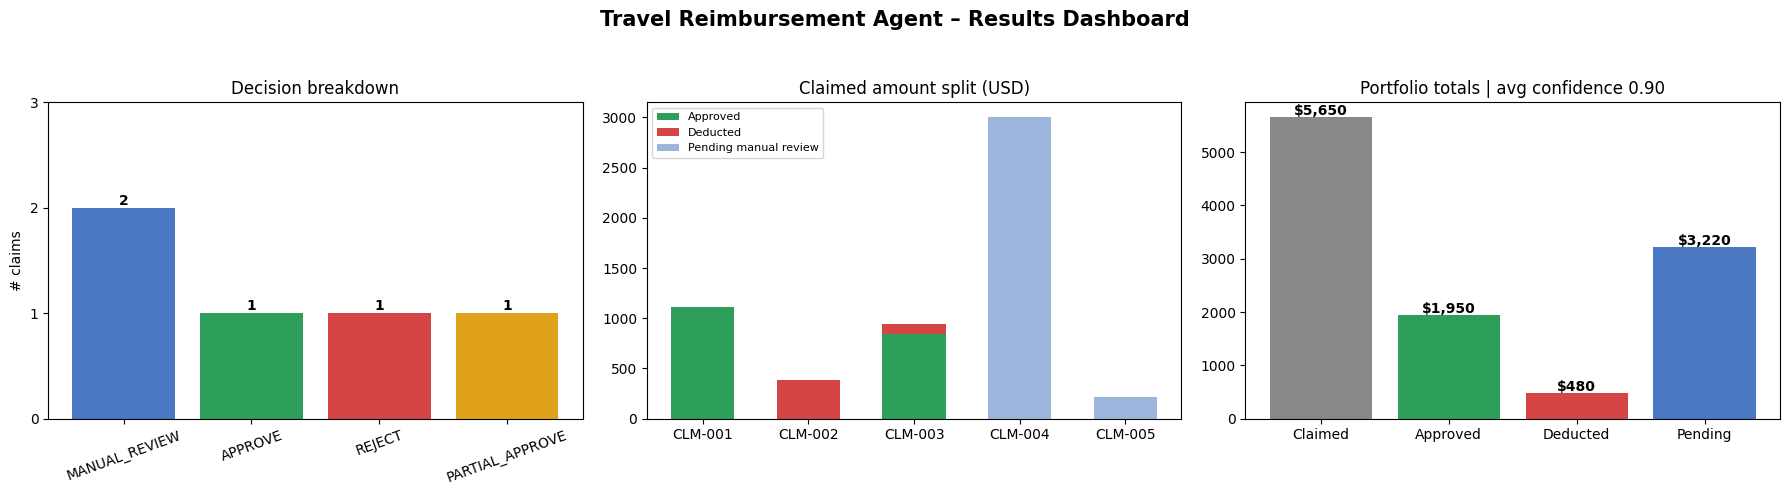

,decision,claims,claimed,approved,deducted
0,APPROVE,1,1110.0,1110.0,0.0
1,MANUAL_REVIEW,2,3220.0,0.0,0.0
2,PARTIAL_APPROVE,1,940.0,840.0,100.0
3,REJECT,1,380.0,0.0,380.0


In [13]:
import matplotlib.pyplot as plt
import numpy as np

dash = pd.DataFrame(RESULTS)
dash["claimed"] = dash["claim_id"].map(claimed)
dash["pending"] = np.where(dash["decision"] == "MANUAL_REVIEW", dash["claimed"], 0.0)   # amount awaiting a human

colors = {"APPROVE": "#2e9e5b", "PARTIAL_APPROVE": "#e0a21b", "REJECT": "#d64545", "MANUAL_REVIEW": "#4a78c2"}
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Travel Reimbursement Agent – Results Dashboard", fontsize=15, fontweight="bold")

# 1) decision breakdown
cnt = dash["decision"].value_counts()
ax[0].bar(cnt.index, cnt.values, color=[colors[d] for d in cnt.index])
for i, v in enumerate(cnt.values): ax[0].text(i, v + .03, str(v), ha="center", fontweight="bold")
ax[0].set_title("Decision breakdown"); ax[0].set_ylabel("# claims"); ax[0].tick_params(axis="x", rotation=20)
ax[0].set_yticks(range(0, int(cnt.max()) + 2))

# 2) approved vs deducted vs pending per claim
x = np.arange(len(dash)); w = .6
ax[1].bar(x, dash["approved_amount"], w, label="Approved", color="#2e9e5b")
ax[1].bar(x, dash["deducted_amount"], w, bottom=dash["approved_amount"], label="Deducted", color="#d64545")
ax[1].bar(x, dash["pending"], w, bottom=dash["approved_amount"] + dash["deducted_amount"], label="Pending manual review", color="#4a78c2", alpha=.55)
ax[1].set_xticks(x); ax[1].set_xticklabels(dash["claim_id"]); ax[1].set_title("Claimed amount split (USD)"); ax[1].legend(fontsize=8)

# 3) totals + confidence
tot = {"Claimed": dash["claimed"].sum(), "Approved": dash["approved_amount"].sum(),
       "Deducted": dash["deducted_amount"].sum(), "Pending": dash["pending"].sum()}
bars = ax[2].bar(tot.keys(), tot.values(), color=["#888", "#2e9e5b", "#d64545", "#4a78c2"])
for b, v in zip(bars, tot.values()): ax[2].text(b.get_x() + b.get_width() / 2, v + 40, f"${v:,.0f}", ha="center", fontweight="bold")
ax[2].set_title(f"Portfolio totals | avg confidence {dash['confidence'].mean():.2f}")
plt.tight_layout(rect=[0, 0, 1, .94])
plt.savefig("UI SS_1.png", dpi=150, bbox_inches="tight")
plt.show()

summary = dash.groupby("decision").agg(claims=("claim_id", "count"), claimed=("claimed", "sum"),
                                       approved=("approved_amount", "sum"), deducted=("deducted_amount", "sum")).reset_index()
display(summary)

## Interactive UI
Select a sample claim **or** choose *Custom JSON* and paste your own claim, then click **Evaluate claim**. The agent runs live (LLM if a key is configured, otherwise offline) and shows the decision card, the tools it called and the guardrail notes.

In [14]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

CUSTOM_TEMPLATE = json.dumps({
    "claim_id": "CLM-CUSTOM", "employee": "Demo User", "purpose": "Customer workshop (business)",
    "trip_start": "2026-06-20", "trip_end": "2026-06-21", "submitted": "2026-06-30",
    "items": [
        {"category": "ground_transport", "description": "Taxi to client site, 2 days", "amount": 130.0, "receipt": True, "quantity": 2, "unit": "day"},
        {"category": "meals", "description": "Meals, 2 days", "amount": 120.0, "receipt": True, "quantity": 2, "unit": "day"}]}, indent=2)

dd   = widgets.Dropdown(options=SAMPLE_IDS + ["Custom JSON"], description="Claim:", layout=widgets.Layout(width="260px"))
ta   = widgets.Textarea(value=CUSTOM_TEMPLATE, layout=widgets.Layout(width="95%", height="210px"), description="")
ta_box = widgets.VBox([widgets.HTML("<b>Custom claim JSON</b>"), ta])
ta_box.layout.display = "none"
btn  = widgets.Button(description="Evaluate claim", button_style="primary", icon="check")
out  = widgets.Output()
BADGE = {"APPROVE": "#2e9e5b", "PARTIAL_APPROVE": "#e0a21b", "REJECT": "#d64545", "MANUAL_REVIEW": "#4a78c2"}

def on_change(_):
    ta_box.layout.display = "block" if dd.value == "Custom JSON" else "none"
dd.observe(on_change, names="value")

def on_click(_):
    with out:
        clear_output()
        try:
            if dd.value == "Custom JSON":
                cid = load_claims(ta.value)[0]
            else:
                cid = dd.value
            res = process_claim(cid)
            au  = AUDIT[cid]
            c   = BADGE[res["decision"]]
            html = f"""
            <div style="border:1px solid #ccc;border-left:8px solid {c};border-radius:8px;padding:14px;max-width:900px;font-family:sans-serif">
              <div style="font-size:18px"><b>{res['claim_id']}</b>
                <span style="background:{c};color:#fff;padding:3px 10px;border-radius:12px;font-size:14px;margin-left:8px">{res['decision']}</span></div>
              <p style="margin:8px 0"><b>Approved:</b> ${res['approved_amount']:,.2f} &nbsp;|&nbsp; <b>Deducted:</b> ${res['deducted_amount']:,.2f} &nbsp;|&nbsp; <b>Confidence:</b> {res['confidence']}</p>
              <p style="margin:8px 0"><b>Explanation:</b> {res['explanation']}</p>
              <p style="margin:8px 0"><b>Policy refs:</b> {', '.join(res['policy_refs'])}</p>
              <p style="margin:8px 0"><b>Missing docs:</b> {'; '.join(res['missing_docs']) or 'none'}</p>
              <p style="margin:8px 0"><b>Tools used:</b> {', '.join(res['tools_used'])} &nbsp;<i>(mode: {au['mode']})</i></p>
              <p style="margin:8px 0;color:#666"><b>Guardrail notes:</b> {'; '.join(au['guardrail_notes']) or 'none'}</p>
            </div>"""
            display(HTML(html))
        except Exception as e:
            display(HTML(f"<span style='color:#d64545'>⚠️ Could not evaluate claim: {e}</span>"))
btn.on_click(on_click)
display(widgets.VBox([widgets.HBox([dd, btn]), ta_box, out]))

## Design Notes & Reasoning

### Approach in one paragraph
A **hybrid agent**: Gemini decides which tools to call and writes the explanation; deterministic Python tools do every rule check and calculation; a validator reconciles the two. This gives the "GenAI reasoning + tool use" the brief asks for without trusting an LLM with arithmetic or money.

### Business-rule assumptions
1. **Per-day / per-night units** come from the claim text (`3 days`, `2 nights`) and are encoded as `quantity`. I used the stated counts rather than trip dates (e.g. CLM-003's trip spans 3 calendar days but meals state 2 days; $140 is under either cap).
2. **Timeliness** is measured from the *earliest* expense date (`trip_start`) – the conservative choice. All five sample claims are well inside 30 days.
3. **Threshold uses reimbursable total after deductions** (as Appendix A says): CLM-003 is evaluated on $840, not $940.
4. **Manual-review amounts:** for `MANUAL_REVIEW` I output `approved_amount = 0` and `deducted_amount = 0` because nothing is final until a human decides. A provisional figure is kept in the explanation/audit trail.
5. **Business/first class** is never auto-deducted (POL-AIR-01) – a pre-approval may exist.

### Why each Manual Review case is routed there
* **CLM-004** – three independent triggers: business-class fare (POL-AIR-01), lodging receipt missing (POL-RCT-01/02) and reimbursable total $3,000 > $2,000 (POL-APR-03). Any one alone is sufficient.
* **CLM-005** – a $220 meal has no receipt (POL-RCT-01/02) *and* a 4-person client dinner makes the $75/day cap ambiguous (is it per person? is entertainment allowed?). Silently deducting $145 or rejecting would be wrong; the reviewer should request the receipt and attendee list.

### Other decisions
* **CLM-001 → APPROVE** ($1,110, manager tier, nothing exceeds a cap). **CLM-002 → REJECT** (spa + minibar are POL-CAT-02, $380 deducted). **CLM-003 → PARTIAL_APPROVE** (lodging $500 vs cap $400 → $100 deducted, approved $840).

### Reliability design
* Tool-calling loop with a **step cap**, **retry/backoff** on rate limits and a **second model** as fallback.
* **Offline fallback agent** – the notebook still runs end-to-end without a key or if the API is down.
* **Guardrail:** amounts/decision always verified against the rule engine; hallucinated policy ids are dropped; every override is logged in the audit trail.
* `tools_used` is captured from real calls, not from the model's self-report.
* Strict output contract asserted in code (`OUTPUT_FIELDS`) and checked by the evaluation cell.

### Trade-offs
* Rule engine + LLM duplicates some logic. I accepted that for safety; in production I'd let the engine be the only authority and use the LLM for unstructured evidence (receipt images, free-text justifications).
* Keyword policy retrieval instead of vector search – the policy is ~12 short rules, so embeddings would be over-engineering.
* Quantities are structured input; in reality the LLM would extract them from free text/receipts.

### Known gaps & next steps
* Receipt OCR / vision (Gemini multimodal) to validate amounts, dates and vendors rather than a boolean `receipt` flag.
* Duplicate-claim detection, FX conversion for international trips, per-person meal logic and pre-approval lookup (so business-class can be auto-cleared when approved).
* Calibrated confidence (currently LLM-reported, capped when overridden) and reason codes returned as a structured field.
* Larger evaluation set + LLM-vs-engine agreement metrics; MCP server exposing the tools.
* Persist the audit trail and add reviewer UI for the manual-review queue.

In [15]:
# FINAL RESULTS - JSON array, one object per provided claim (exact required fields)
FINAL_RESULTS = [{k: r[k] for k in OUTPUT_FIELDS} for r in RESULTS]
assert len(FINAL_RESULTS) == 5 and all(list(r.keys()) == OUTPUT_FIELDS for r in FINAL_RESULTS)
print(json.dumps(FINAL_RESULTS, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-AIR-01",
      "POL-APR-02",
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01"
    ],
    "confidence": 0.95,
    "explanation": "All items eligible (POL-CAT-01), within per-diem limits, receipts attached. Total reimbursable $1,110.00 falls in tier POL-APR-02 - MANAGER (> $500 and <= $2,000); all required receipts present and submitted on time (POL-RCT-01, POL-TIME-01).",
    "tools_used": [
      "get_claim",
      "lookup_policy",
      "check_eligibility",
      "check_limits",
      "check_receipts",
      "check_timeliness",
      "check_approval_threshold"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-02"
    ],
    "confidence": 0.95,
    "exp